# Lieferverzögerung & Kundenzufriedenheit im E-Commerce

**Datenprojekt Business Analytics – DHBW Bad Mergentheim, Digital Business Management**
**Gruppe 3:** Luisa Krenz & Sophia Menzel
**Dozent:** Thomas Burghardt
**Methode:** Vibe Coding (Python-Code mit Unterstützung eines Sprachmodells erstellt, von uns geprüft und interpretiert)

---

### Forschungsfrage
> Welchen Zusammenhang gibt es zwischen Lieferverzögerungen und Kundenbewertungen im E-Commerce und in welchen Regionen treten Verzögerungen besonders häufig auf?

### Hypothesen
| | Hypothese |
|---|---|
| **H1** | Verspätete Lieferungen werden schlechter bewertet als pünktliche. |
| **H2** | Mit zunehmender Verzögerung sinkt die Bewertung. |
| **H3** | Die Verspätungsquote unterscheidet sich zwischen den brasilianischen Bundesstaaten. |
| **H4** | Auch die Gesamtlieferzeit steht mit der Kundenbewertung in Zusammenhang. |

### Aufbau des Notebooks
Wir folgen den fünf Phasen einer statistischen Untersuchung aus der Vorlesung:

1. Vorbereitung
2. Datenerhebung (Daten laden & beschreiben)
3. Aufbereitung (Bereinigung, Verknüpfung, neue Variablen)
4. Datenauswertung & -analyse (H1–H4)
5. Ergebnispräsentation (Fazit, Handlungsempfehlungen, Grenzen)

## Phase 1 – Vorbereitung

**Ziel:** Den Zusammenhang zwischen Lieferperformance und Kundenzufriedenheit quantitativ untersuchen und regionale Unterschiede bei Lieferverzögerungen identifizieren. Daraus leiten wir Ansatzpunkte für die Logistik von Olist ab.

**Abgrenzung des Untersuchungsgegenstands:**
- Betrachtet werden nur Bestellungen mit Status `delivered` **und** vorhandenem Lieferdatum – nur bei ihnen lässt sich eine Verspätung messen.
- Kundenzufriedenheit = Sternebewertung (`review_score`, 1–5).
- Region = Bundesstaat des Kunden (`customer_state`, 27 Bundesstaaten).

**Definitionen:**
- **Verzögerung (Tage)** = tatsächliches Lieferdatum − geschätztes Lieferdatum (in Kalendertagen). Negativ = früher als angekündigt.
- **Verspätet** = Lieferung kam an einem *späteren Kalendertag* als angekündigt (Verzögerung > 0).
- **Gesamtlieferzeit (Tage)** = Zeit vom Kauf bis zur Zustellung beim Kunden.

### Bibliotheken laden

In [1]:
import pandas as pd                 # Tabellen laden & bearbeiten
import numpy as np                  # Rechnen
import matplotlib.pyplot as plt     # Diagramme
import seaborn as sns               # schönere Diagramme
from scipy import stats             # statistische Tests

# Einheitlicher Diagramm-Stil
sns.set_theme(style="whitegrid", font_scale=1.05)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

# Feste Farben: Blau = pünktlich, Orange = verspätet (gleich in allen Diagrammen)
BLAU, ORANGE, GRAU = "#2a78d6", "#eb6834", "#8a8984"

pd.set_option("display.float_format", "{:.2f}".format)

def p_text(p):
    # p-Werte lesbar ausgeben (sehr kleine p-Werte würden sonst als 0 angezeigt)
    return "< 0,001" if p < 0.001 else f"{p:.3f}"

## Phase 2 – Datenerhebung

Es handelt sich um eine **Sekundärerhebung**: Wir nutzen das öffentlich verfügbare *Brazilian E-Commerce Public Dataset by Olist* von Kaggle.

| Merkmal | Beschreibung |
|---|---|
| Quelle | Olist (2018), Kaggle: https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce |
| Lizenz | CC BY-NC-SA 4.0 (nicht-kommerzielle Nutzung mit Namensnennung) |
| Zeitraum | September 2016 – Oktober 2018 |
| Ort | Brasilien |
| Umfang | ca. 100.000 anonymisierte Bestellungen |

Vom Gesamtdatensatz (9 Tabellen) nutzen wir – wie mit dem Dozenten abgestimmt – nur **drei Tabellen**:

| Tabelle | Wichtige Spalten | Schlüssel |
|---|---|---|
| `orders` | Status, Kaufdatum, tatsächliches & geschätztes Lieferdatum | `order_id`, `customer_id` |
| `order_reviews` | Bewertung (1–5 Sterne), Kommentar | `order_id` |
| `customers` | Stadt, Bundesstaat | `customer_id` |

**Beziehungen:** `orders` ist die zentrale Tabelle. Über `order_id` hängen die Bewertungen dran, über `customer_id` die Kundendaten.

```
customers  ──(customer_id)──  orders  ──(order_id)──  order_reviews
```

In [2]:
# Die CSV-Dateien liegen im selben Ordner wie dieses Notebook (siehe README)
orders    = pd.read_csv("mgh-dbm25-gruppe03-olist_orders_dataset.csv")
reviews   = pd.read_csv("mgh-dbm25-gruppe03-olist_order_reviews_dataset.csv")
customers = pd.read_csv("mgh-dbm25-gruppe03-olist_customers_dataset.csv",
                        dtype={"customer_zip_code_prefix": str})  # PLZ als Text, sonst gehen führende Nullen verloren

for name, df in [("orders", orders), ("order_reviews", reviews), ("customers", customers)]:
    print(f"{name:14s}: {df.shape[0]:>7,} Zeilen, {df.shape[1]} Spalten")

orders        :  99,441 Zeilen, 8 Spalten
order_reviews :  99,224 Zeilen, 7 Spalten
customers     :  99,441 Zeilen, 5 Spalten


### Ein erster Blick in die Tabellen

In [3]:
orders.head(3)

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00


In [4]:
reviews.head(3)

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24


In [5]:
customers.head(3)

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,09790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,01151,sao paulo,SP


## Phase 3 – Aufbereitung

### 3.1 Datenqualität prüfen
Wir prüfen fehlende Werte, Datentypen und Duplikate, bevor wir rechnen.

In [6]:
print("Fehlende Werte in orders:")
print(orders.isna().sum())

Fehlende Werte in orders:
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64


In [7]:
print("Bestellstatus:")
print(orders["order_status"].value_counts())

Bestellstatus:
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64


In [8]:
# Gibt es Bestellungen mit mehreren Bewertungen?
mehrfach = reviews["order_id"].duplicated().sum()
print(f"Bewertungen zu bereits bewerteten Bestellungen (Duplikate nach order_id): {mehrfach}")
print(f"Doppelte Kunden-IDs in customers: {customers['customer_id'].duplicated().sum()}")

Bewertungen zu bereits bewerteten Bestellungen (Duplikate nach order_id): 551
Doppelte Kunden-IDs in customers: 0


**Befund:**
- Rund 3 % der Bestellungen haben **kein Lieferdatum** – das sind v. a. stornierte, noch versendete oder nicht verfügbare Bestellungen.
- Einige Bestellungen wurden **mehrfach bewertet**. Damit jede Bestellung nur einmal zählt, behalten wir jeweils die **zuletzt beantwortete** Bewertung.
- Die Datumsangaben sind als Text gespeichert und müssen in echte Datumswerte umgewandelt werden.

### 3.2 Bereinigung

In [9]:
# 1) Datumsspalten in echte Datumswerte umwandeln
datums_spalten = ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
                  "order_delivered_customer_date", "order_estimated_delivery_date"]
for spalte in datums_spalten:
    orders[spalte] = pd.to_datetime(orders[spalte])

# 2) Nur zugestellte Bestellungen mit Lieferdatum behalten
geliefert = orders[(orders["order_status"] == "delivered") &
                   (orders["order_delivered_customer_date"].notna())].copy()
print(f"Bestellungen gesamt:            {len(orders):>7,}")
print(f"davon zugestellt mit Datum:     {len(geliefert):>7,}  ({len(geliefert)/len(orders):.1%})")

# 3) Pro Bestellung nur eine Bewertung (die zuletzt beantwortete)
reviews_eindeutig = (reviews.sort_values("review_answer_timestamp")
                            .drop_duplicates(subset="order_id", keep="last"))
print(f"Bewertungen vorher / nachher:   {len(reviews):>7,} / {len(reviews_eindeutig):,}")

Bestellungen gesamt:             99,441
davon zugestellt mit Datum:      96,470  (97.0%)


Bewertungen vorher / nachher:    99,224 / 98,673


### 3.3 Neue Variablen berechnen

In [10]:
# Verzögerung in Kalendertagen: tatsächliche Lieferung minus angekündigte Lieferung
# (.dt.normalize() setzt die Uhrzeit auf 00:00, damit wir ganze Tage vergleichen)
geliefert["verzoegerung_tage"] = (geliefert["order_delivered_customer_date"].dt.normalize()
                                  - geliefert["order_estimated_delivery_date"]).dt.days

# Verspätet = Lieferung an einem späteren Tag als angekündigt
geliefert["verspaetet"] = geliefert["verzoegerung_tage"] > 0

# Gesamtlieferzeit vom Kauf bis zur Zustellung (in Tagen, mit Nachkommastellen)
geliefert["lieferzeit_tage"] = ((geliefert["order_delivered_customer_date"]
                                 - geliefert["order_purchase_timestamp"]).dt.total_seconds() / 86400)

geliefert[["verzoegerung_tage", "verspaetet", "lieferzeit_tage"]].head()

,verzoegerung_tage,verspaetet,lieferzeit_tage
0,-8,False,8.44
1,-6,False,13.78
2,-18,False,9.39
3,-13,False,13.21
4,-10,False,2.87


### 3.4 Tabellen verknüpfen

In [11]:
df = (geliefert
      .merge(reviews_eindeutig[["order_id", "review_score"]], on="order_id", how="inner")
      .merge(customers[["customer_id", "customer_city", "customer_state"]], on="customer_id", how="inner"))

print(f"Analysedatensatz: {len(df):,} Bestellungen mit Lieferdatum, Bewertung und Region")
df[["order_id", "customer_state", "verzoegerung_tage", "verspaetet", "lieferzeit_tage", "review_score"]].head()

Analysedatensatz: 95,824 Bestellungen mit Lieferdatum, Bewertung und Region


,order_id,customer_state,verzoegerung_tage,verspaetet,lieferzeit_tage,review_score
0,e481f51cbdc54678b7cc49136f2d6af7,SP,-8,False,8.44,4
1,53cdb2fc8bc7dce0b6741e2150273451,BA,-6,False,13.78,4
2,47770eb9100c2d0c44946d9cf07ec65d,GO,-18,False,9.39,5
3,949d5b44dbf5de918fe9c16f97b45f8a,RN,-13,False,13.21,5
4,ad21c59c0840e6cb83a9ceb5573f8159,SP,-10,False,2.87,5


## Phase 4 – Datenauswertung & -analyse

### 4.1 Deskriptive Statistik – Überblick

In [12]:
kennzahlen = df[["review_score", "verzoegerung_tage", "lieferzeit_tage"]].describe().T
kennzahlen["Median"] = df[["review_score", "verzoegerung_tage", "lieferzeit_tage"]].median()
kennzahlen["Varianz"] = df[["review_score", "verzoegerung_tage", "lieferzeit_tage"]].var()
kennzahlen

,count,mean,std,min,25%,50%,75%,max,Median,Varianz
review_score,95824.00,4.16,1.28,1.00,4.00,5.00,5.00,5.00,5.00,1.65
verzoegerung_tage,95824.00,-11.91,10.11,-147.00,-17.00,-12.00,-7.00,188.00,-12.00,102.25
lieferzeit_tage,95824.00,12.52,9.46,0.53,6.76,10.21,15.66,208.35,10.21,89.50


In [13]:
quote = df["verspaetet"].mean()
print(f"Verspätungsquote gesamt: {quote:.1%}  ({df['verspaetet'].sum():,} von {len(df):,} Bestellungen)")
print(f"Durchschnittliche Lieferzeit: {df['lieferzeit_tage'].mean():.1f} Tage (Median {df['lieferzeit_tage'].median():.1f})")
print(f"Im Mittel kommt eine Bestellung {-df['verzoegerung_tage'].median():.0f} Tage VOR dem angekündigten Termin an (Median).")

Verspätungsquote gesamt: 6.7%  (6,381 von 95,824 Bestellungen)
Durchschnittliche Lieferzeit: 12.5 Tage (Median 10.2)
Im Mittel kommt eine Bestellung 12 Tage VOR dem angekündigten Termin an (Median).


#### Häufigkeitsverteilung der Bewertungen

In [14]:
haeufigkeit = pd.DataFrame({
    "absolute Häufigkeit": df["review_score"].value_counts().sort_index(),
    "relative Häufigkeit": df["review_score"].value_counts(normalize=True).sort_index()
})
haeufigkeit["kumuliert"] = haeufigkeit["relative Häufigkeit"].cumsum()
haeufigkeit.index.name = "Sterne"
haeufigkeit.style.format({"absolute Häufigkeit": "{:,}", "relative Häufigkeit": "{:.1%}", "kumuliert": "{:.1%}"})

,absolute Häufigkeit,relative Häufigkeit,kumuliert
Sterne,,,
1,"9,351",9.8%,9.8%
2,"2,921",3.0%,12.8%
3,"7,916",8.3%,21.1%
4,"18,888",19.7%,40.8%
5,"56,748",59.2%,100.0%


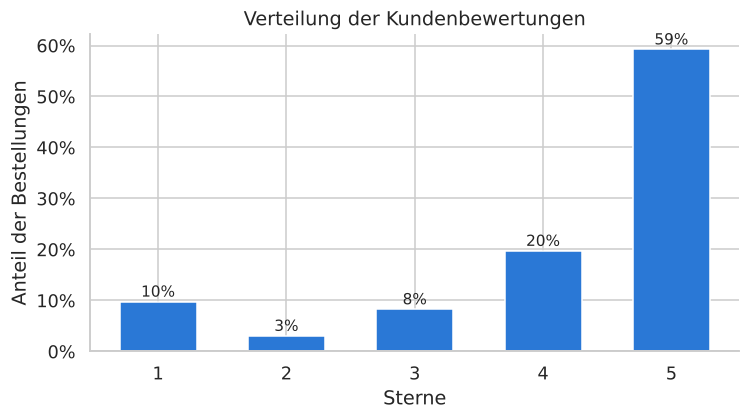

In [15]:
fig, ax = plt.subplots(figsize=(7, 4))
werte = haeufigkeit["relative Häufigkeit"]
ax.bar(werte.index, werte.values, color=BLAU, width=0.6)
for x, y in zip(werte.index, werte.values):
    ax.text(x, y + 0.01, f"{y:.0%}", ha="center", fontsize=10)
ax.set(title="Verteilung der Kundenbewertungen", xlabel="Sterne", ylabel="Anteil der Bestellungen")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
plt.tight_layout(); plt.show()

**Interpretation:** Die Bewertungen sind stark **linksschief** – die meisten Kunden vergeben 5 Sterne. Gleichzeitig gibt es eine auffällige Häufung bei 1 Stern. Weil die Bewertung nur 5 geordnete Stufen hat (ordinales Skalenniveau) und nicht normalverteilt ist, verwenden wir in den Tests **nichtparametrische Verfahren** (Mann-Whitney-U, Kruskal-Wallis, Spearman).

---
### 4.2 H1 – Verspätete Lieferungen werden schlechter bewertet als pünktliche

In [16]:
h1 = (df.groupby("verspaetet")["review_score"]
        .agg(Anzahl="count", Mittelwert="mean", Median="median", Standardabw="std"))
h1.index = h1.index.map({False: "pünktlich", True: "verspätet"})
h1

,Anzahl,Mittelwert,Median,Standardabw
verspaetet,,,,
pünktlich,89443,4.29,5.00,1.15
verspätet,6381,2.27,1.00,1.57


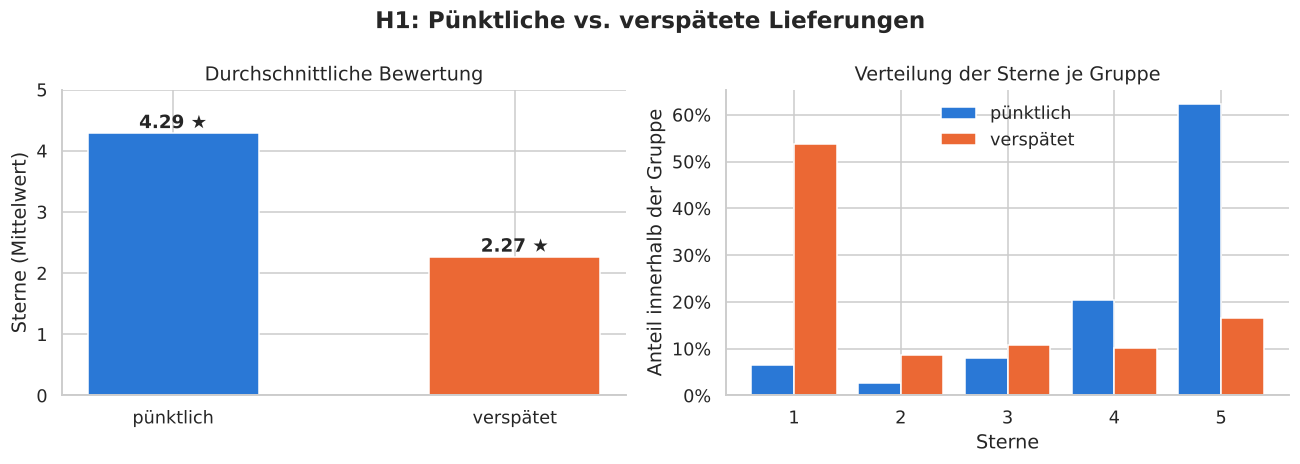

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))

# Links: Durchschnittliche Bewertung
ax = axes[0]
ax.bar(h1.index, h1["Mittelwert"], color=[BLAU, ORANGE], width=0.5)
for i, v in enumerate(h1["Mittelwert"]):
    ax.text(i, v + 0.08, f"{v:.2f} ★", ha="center", fontsize=12, fontweight="bold")
ax.set(title="Durchschnittliche Bewertung", ylabel="Sterne (Mittelwert)", ylim=(0, 5))

# Rechts: Verteilung der Sterne je Gruppe
ax = axes[1]
verteilung = pd.crosstab(df["review_score"], df["verspaetet"], normalize="columns")
x = np.arange(1, 6)
ax.bar(x - 0.2, verteilung[False], width=0.4, color=BLAU, label="pünktlich")
ax.bar(x + 0.2, verteilung[True],  width=0.4, color=ORANGE, label="verspätet")
ax.set(title="Verteilung der Sterne je Gruppe", xlabel="Sterne", ylabel="Anteil innerhalb der Gruppe", xticks=x)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.legend(frameon=False)

plt.suptitle("H1: Pünktliche vs. verspätete Lieferungen", fontweight="bold")
plt.tight_layout(); plt.show()

In [18]:
puenktlich = df.loc[~df["verspaetet"], "review_score"]
verspaetet = df.loc[ df["verspaetet"], "review_score"]

# Mann-Whitney-U-Test: Sind verspätete Bewertungen systematisch niedriger?
u, p = stats.mannwhitneyu(verspaetet, puenktlich, alternative="less")

# Effektstärke r = Z / sqrt(N)  (|r| ≈ 0,1 klein, 0,3 mittel, 0,5 groß)
n1, n2 = len(verspaetet), len(puenktlich)
z = (u - n1 * n2 / 2) / np.sqrt(n1 * n2 * (n1 + n2 + 1) / 12)
r = z / np.sqrt(n1 + n2)

print(f"Mittelwert pünktlich: {puenktlich.mean():.2f} | verspätet: {verspaetet.mean():.2f} | Differenz: {puenktlich.mean()-verspaetet.mean():.2f} Sterne")
print(f"Anteil 1-Stern-Bewertungen: pünktlich {(puenktlich==1).mean():.1%} | verspätet {(verspaetet==1).mean():.1%}")
print(f"Mann-Whitney-U: U = {u:,.0f}, p {p_text(p)}")
print(f"Effektstärke |r| = {abs(r):.2f}")

Mittelwert pünktlich: 4.29 | verspätet: 2.27 | Differenz: 2.02 Sterne
Anteil 1-Stern-Bewertungen: pünktlich 6.6% | verspätet 53.8%
Mann-Whitney-U: U = 103,305,546, p < 0,001
Effektstärke |r| = 0.28


**Ergebnis H1:** ✅ **bestätigt.** Verspätete Bestellungen werden im Schnitt rund **2 Sterne schlechter** bewertet (≈ 2,3 statt ≈ 4,3). Mehr als die Hälfte der verspäteten Bestellungen bekommt nur **1 Stern** (≈ 54 % gegenüber ≈ 7 % bei pünktlichen). Der Unterschied ist hoch signifikant (p < 0,001), die Effektstärke ist **klein bis mittel** (|r| ≈ 0,28).

---
### 4.3 H2 – Mit zunehmender Verzögerung sinkt die Bewertung

Wir teilen die Bestellungen in Klassen nach der Verzögerung ein (früh, pünktlich, 1–3 Tage zu spät usw.).

In [19]:
klassen_grenzen = [-np.inf, -8, -1, 0, 3, 7, 14, np.inf]
klassen_namen   = ["> 7 Tage früher", "1–7 Tage früher", "am Tag", "1–3 Tage zu spät",
                   "4–7 Tage zu spät", "8–14 Tage zu spät", "> 14 Tage zu spät"]
df["verzoegerung_klasse"] = pd.cut(df["verzoegerung_tage"], bins=klassen_grenzen, labels=klassen_namen)

h2 = (df.groupby("verzoegerung_klasse", observed=True)["review_score"]
        .agg(Anzahl="count", Mittelwert="mean", Median="median"))
h2["Anteil 1 Stern"] = df.groupby("verzoegerung_klasse", observed=True)["review_score"].apply(lambda s: (s == 1).mean())
h2.style.format({"Anzahl": "{:,}", "Mittelwert": "{:.2f}", "Median": "{:.0f}", "Anteil 1 Stern": "{:.1%}"})

,Anzahl,Mittelwert,Median,Anteil 1 Stern
verzoegerung_klasse,,,,
> 7 Tage früher,"70,929",4.32,5,6.5%
1–7 Tage früher,"17,234",4.20,5,7.1%
am Tag,"1,280",4.03,5,8.5%
1–3 Tage zu spät,"1,852",3.29,4,25.1%
4–7 Tage zu spät,"1,748",2.10,1,58.6%
8–14 Tage zu spät,"1,446",1.67,1,70.6%
> 14 Tage zu spät,"1,335",1.72,1,69.0%


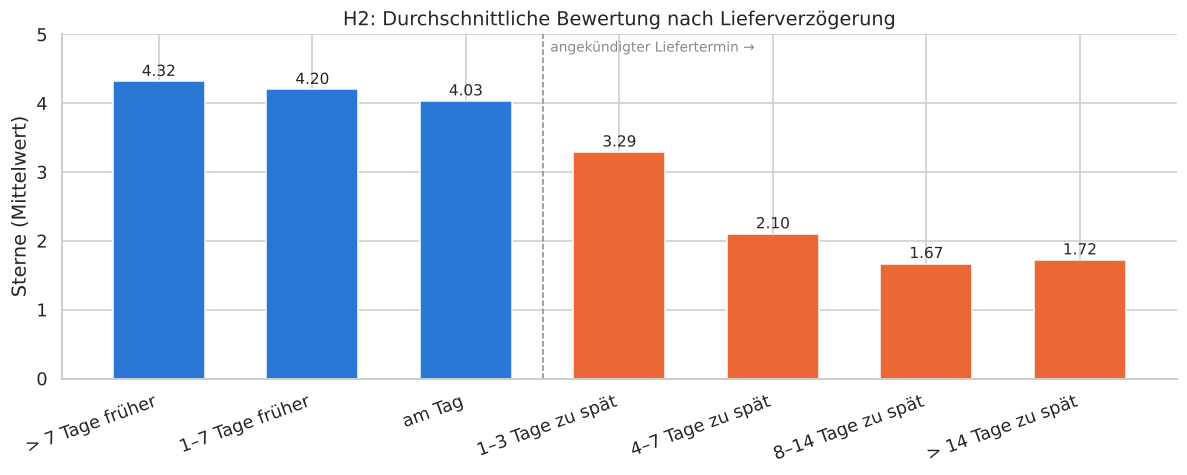

In [20]:
fig, ax = plt.subplots(figsize=(11, 4.5))
farben = [BLAU] * 3 + [ORANGE] * 4
ax.bar(range(len(h2)), h2["Mittelwert"], color=farben, width=0.6)
for i, v in enumerate(h2["Mittelwert"]):
    ax.text(i, v + 0.08, f"{v:.2f}", ha="center", fontsize=10)
ax.set_xticks(range(len(h2)), h2.index, rotation=20, ha="right")
ax.set(title="H2: Durchschnittliche Bewertung nach Lieferverzögerung", ylabel="Sterne (Mittelwert)", ylim=(0, 5))
ax.axvline(2.5, color=GRAU, linestyle="--", linewidth=1)
ax.text(2.55, 4.75, "angekündigter Liefertermin →", color=GRAU, fontsize=9)
plt.tight_layout(); plt.show()

In [21]:
# Spearman-Rangkorrelation: Verzögerung (Tage) vs. Bewertung
rho_alle, p_alle = stats.spearmanr(df["verzoegerung_tage"], df["review_score"])

# Nur innerhalb der verspäteten Bestellungen: wird es mit jedem Tag schlechter?
nur_spaet = df[df["verspaetet"]]
rho_spaet, p_spaet = stats.spearmanr(nur_spaet["verzoegerung_tage"], nur_spaet["review_score"])

# Kruskal-Wallis-Test: Unterscheiden sich die Klassen insgesamt?
gruppen = [g["review_score"].values for _, g in df.groupby("verzoegerung_klasse", observed=True)]
h_stat, p_kw = stats.kruskal(*gruppen)

print(f"Spearman (alle Bestellungen):        rho = {rho_alle:.3f}, p {p_text(p_alle)}")
print(f"Spearman (nur verspätete):           rho = {rho_spaet:.3f}, p {p_text(p_spaet)}")
print(f"Kruskal-Wallis über alle Klassen:    H = {h_stat:,.0f}, p {p_text(p_kw)}")

Spearman (alle Bestellungen):        rho = -0.176, p < 0,001
Spearman (nur verspätete):           rho = -0.402, p < 0,001
Kruskal-Wallis über alle Klassen:    H = 10,375, p < 0,001


**Ergebnis H2:** ✅ **bestätigt.** Je später die Lieferung, desto schlechter die Bewertung. Bis zum angekündigten Termin bleibt die Bewertung stabil bei gut 4 Sternen. Schon bei 1–3 Tagen Verspätung fällt sie auf ≈ 3,3 Sterne, bei 4–7 Tagen auf ≈ 2,1 und ab mehr als einer Woche Verspätung liegt sie im Mittel unter 2 Sternen. Betrachtet man nur die verspäteten Bestellungen, ist die Korrelation zwischen Verzögerungstagen und Bewertung **mittelstark negativ** (rho ≈ −0,40).

Die Korrelation über alle Bestellungen ist nur **schwach negativ**. Das liegt daran, dass die meisten Bestellungen früh ankommen und dort die Bewertung kaum variiert. Der Zusammenhang ist also **nicht linear**: Entscheidend ist vor allem, *ob* der Termin überschritten wird – und danach jeder weitere Tag (bis die Bewertung bei ca. 1,7 Sternen ihren Boden erreicht).

---
### 4.4 H3 – Die Verspätungsquote unterscheidet sich zwischen den Bundesstaaten

In [22]:
h3 = (df.groupby("customer_state")
        .agg(Bestellungen=("order_id", "count"),
             Verspaetungsquote=("verspaetet", "mean"),
             Lieferzeit_Median=("lieferzeit_tage", "median"),
             Bewertung_Mittel=("review_score", "mean"))
        .sort_values("Verspaetungsquote", ascending=False))
h3.style.format({"Bestellungen": "{:,}", "Verspaetungsquote": "{:.1%}",
                 "Lieferzeit_Median": "{:.1f}", "Bewertung_Mittel": "{:.2f}"})

,Bestellungen,Verspaetungsquote,Lieferzeit_Median,Bewertung_Mittel
customer_state,,,,
AL,394,20.8%,22.3,3.85
MA,712,17.1%,19.1,3.83
SE,334,15.0%,18.0,3.91
PI,471,13.8%,16.3,3.99
CE,"1,273",13.7%,18.2,3.94
RR,41,12.2%,25.0,3.90
RJ,"12,211",11.9%,12.0,3.97
BA,"3,229",11.9%,16.9,3.93
PA,933,10.7%,21.1,3.91


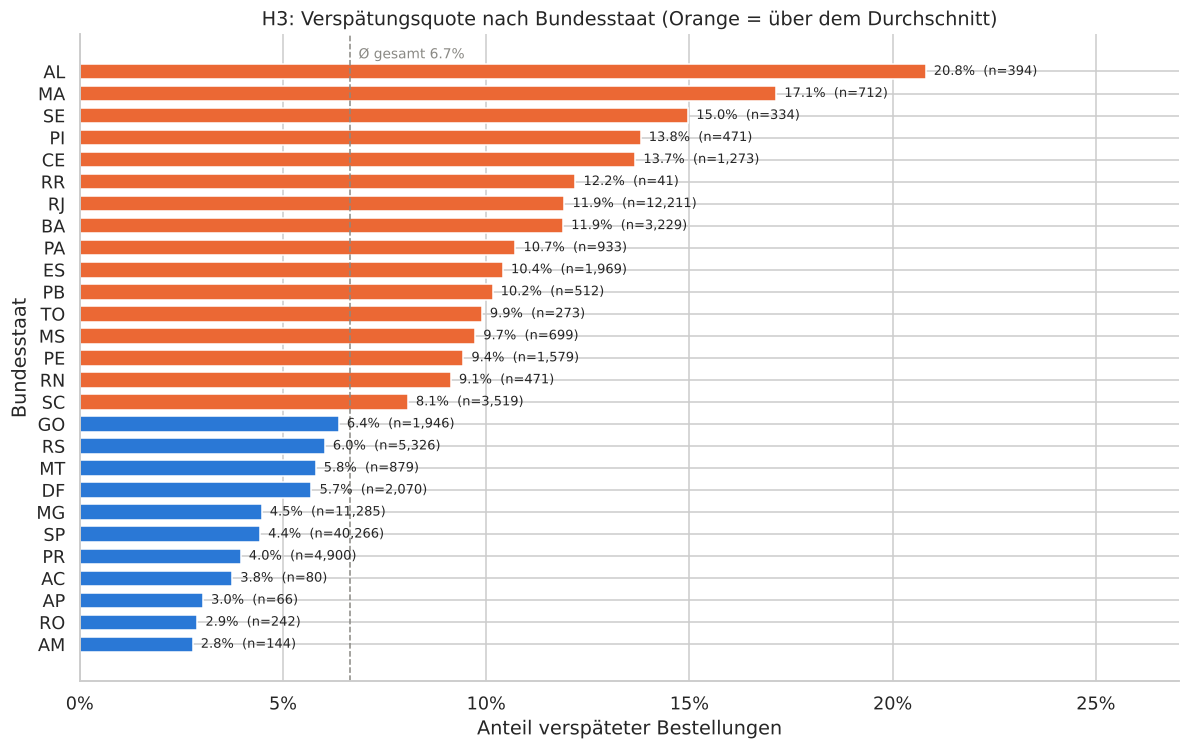

In [23]:
fig, ax = plt.subplots(figsize=(11, 7))
daten = h3.sort_values("Verspaetungsquote")
farben = [ORANGE if q > quote else BLAU for q in daten["Verspaetungsquote"]]
ax.barh(daten.index, daten["Verspaetungsquote"], color=farben, height=0.7)
for i, (q, n) in enumerate(zip(daten["Verspaetungsquote"], daten["Bestellungen"])):
    ax.text(q + 0.002, i, f"{q:.1%}  (n={n:,})", va="center", fontsize=8.5)
ax.axvline(quote, color=GRAU, linestyle="--", linewidth=1)
ax.text(quote + 0.002, len(daten) - 0.4, f"Ø gesamt {quote:.1%}", color=GRAU, fontsize=9)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set(title="H3: Verspätungsquote nach Bundesstaat (Orange = über dem Durchschnitt)",
       xlabel="Anteil verspäteter Bestellungen", ylabel="Bundesstaat", xlim=(0, daten["Verspaetungsquote"].max() * 1.3))
plt.tight_layout(); plt.show()

Zur Einordnung die **Regionen Brasiliens** (Bundesstaaten zusammengefasst):

In [24]:
regionen = {
    "Norden":       ["AC", "AP", "AM", "PA", "RO", "RR", "TO"],
    "Nordosten":    ["AL", "BA", "CE", "MA", "PB", "PE", "PI", "RN", "SE"],
    "Mittelwesten": ["DF", "GO", "MT", "MS"],
    "Südosten":     ["ES", "MG", "RJ", "SP"],
    "Süden":        ["PR", "RS", "SC"],
}
staat_zu_region = {staat: region for region, staaten in regionen.items() for staat in staaten}
df["region"] = df["customer_state"].map(staat_zu_region)

h3_region = (df.groupby("region")
               .agg(Bestellungen=("order_id", "count"), Verspaetungsquote=("verspaetet", "mean"),
                    Lieferzeit_Median=("lieferzeit_tage", "median"), Bewertung_Mittel=("review_score", "mean"))
               .sort_values("Verspaetungsquote", ascending=False))
h3_region.style.format({"Bestellungen": "{:,}", "Verspaetungsquote": "{:.1%}",
                        "Lieferzeit_Median": "{:.1f}", "Bewertung_Mittel": "{:.2f}"})

,Bestellungen,Verspaetungsquote,Lieferzeit_Median,Bewertung_Mittel
region,,,,
Nordosten,"8,975",12.5%,17.3,3.97
Norden,"1,779",8.3%,20.1,4.03
Mittelwesten,"5,594",6.5%,13.3,4.13
Südosten,"65,731",6.0%,8.7,4.18
Süden,"13,745",5.8%,12.1,4.19


In [25]:
# Chi-Quadrat-Unabhängigkeitstest: Hängt "verspätet ja/nein" vom Bundesstaat ab?
kreuztabelle = pd.crosstab(df["customer_state"], df["verspaetet"])
chi2, p_chi, freiheitsgrade, _ = stats.chi2_contingency(kreuztabelle)

# Effektstärke Cramérs V (0,1 klein, 0,3 mittel, 0,5 groß)
cramers_v = np.sqrt(chi2 / (kreuztabelle.values.sum() * (min(kreuztabelle.shape) - 1)))

print(f"Chi² = {chi2:,.1f}, Freiheitsgrade = {freiheitsgrade}, p {p_text(p_chi)}")
print(f"Cramérs V = {cramers_v:.3f}")
print(f"Spannweite der Quoten: {h3['Verspaetungsquote'].min():.1%} ({h3['Verspaetungsquote'].idxmin()}) "
      f"bis {h3['Verspaetungsquote'].max():.1%} ({h3['Verspaetungsquote'].idxmax()})")

Chi² = 1,731.6, Freiheitsgrade = 26, p < 0,001
Cramérs V = 0.134
Spannweite der Quoten: 2.8% (AM) bis 20.8% (AL)


**Ergebnis H3:** ✅ **bestätigt.** Die Verspätungsquote unterscheidet sich signifikant zwischen den Bundesstaaten (Chi²-Test, p < 0,001). Sie reicht von unter 3 % (z. B. AM, RO) bis über 20 % (AL). Besonders betroffen ist der **Nordosten** (z. B. AL, MA, SE, PI, CE) sowie **Rio de Janeiro (RJ)**, das wegen seiner vielen Bestellungen sehr ins Gewicht fällt. Die Effektstärke ist zwar klein (der Großteil der Bestellungen ist überall pünktlich), für die Logistik aber relevant.

**Auffällig:** Einige nördliche Bundesstaaten (z. B. AM, AP, AC) haben zwar mit die *längsten* Lieferzeiten, aber die *wenigsten* Verspätungen. Vermutlich werden dort von vornherein längere Lieferzeiten angekündigt. Verspätung hängt also davon ab, **wie realistisch der angekündigte Termin ist** – nicht nur von der Entfernung.

*Hinweis:* Bei kleinen Bundesstaaten (z. B. RR mit nur ~40 Bestellungen) sind die Quoten weniger belastbar.

---
### 4.5 H4 – Auch die Gesamtlieferzeit steht mit der Kundenbewertung in Zusammenhang

In [26]:
lz_grenzen = [0, 5, 10, 15, 20, 30, np.inf]
lz_namen   = ["≤ 5 Tage", "6–10 Tage", "11–15 Tage", "16–20 Tage", "21–30 Tage", "> 30 Tage"]
df["lieferzeit_klasse"] = pd.cut(df["lieferzeit_tage"], bins=lz_grenzen, labels=lz_namen)

h4 = pd.DataFrame({
    "Anzahl":                   df.groupby("lieferzeit_klasse", observed=True)["review_score"].count(),
    "Ø Bewertung (alle)":       df.groupby("lieferzeit_klasse", observed=True)["review_score"].mean(),
    "Ø Bewertung (nur pünktl.)": df[~df["verspaetet"]].groupby("lieferzeit_klasse", observed=True)["review_score"].mean(),
    "Verspätungsquote":         df.groupby("lieferzeit_klasse", observed=True)["verspaetet"].mean(),
})
h4.style.format({"Anzahl": "{:,}", "Ø Bewertung (alle)": "{:.2f}", "Ø Bewertung (nur pünktl.)": "{:.2f}",
                 "Verspätungsquote": "{:.1%}"})

,Anzahl,Ø Bewertung (alle),Ø Bewertung (nur pünktl.),Verspätungsquote
lieferzeit_klasse,,,,
≤ 5 Tage,"13,374",4.45,4.45,0.1%
6–10 Tage,"32,885",4.36,4.37,0.5%
11–15 Tage,"23,470",4.27,4.28,1.1%
16–20 Tage,"12,077",4.13,4.16,3.0%
21–30 Tage,"9,588",3.68,3.99,22.0%
> 30 Tage,"4,430",2.25,3.67,78.4%


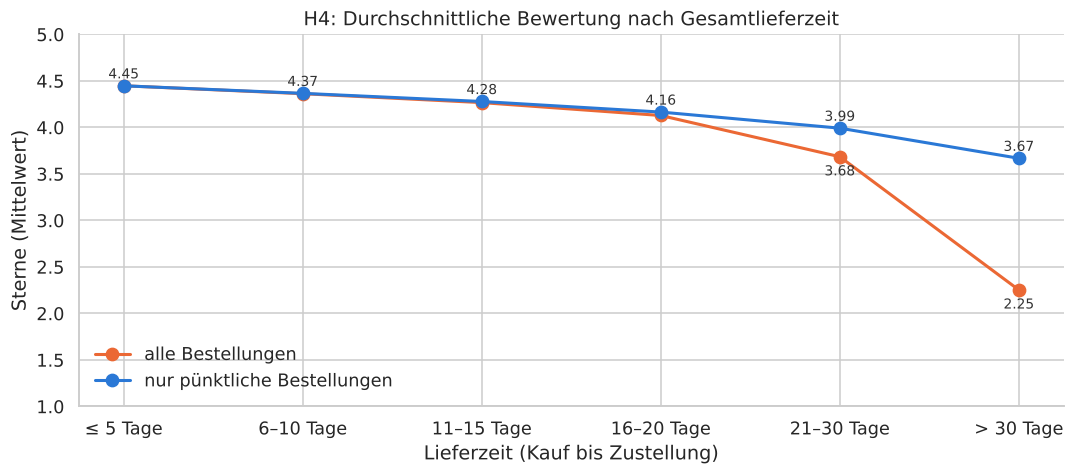

In [27]:
fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(len(h4))
ax.plot(x, h4["Ø Bewertung (alle)"], marker="o", markersize=8, linewidth=2, color=ORANGE, label="alle Bestellungen")
ax.plot(x, h4["Ø Bewertung (nur pünktl.)"], marker="o", markersize=8, linewidth=2, color=BLAU, label="nur pünktliche Bestellungen")
for xi, (a, b) in enumerate(zip(h4["Ø Bewertung (alle)"], h4["Ø Bewertung (nur pünktl.)"])):
    ax.text(xi, b + 0.08, f"{b:.2f}", ha="center", fontsize=9, color="#333")
    if b - a > 0.15:   # nur beschriften, wo sich die Linien deutlich trennen
        ax.text(xi, a - 0.2, f"{a:.2f}", ha="center", fontsize=9, color="#333")
ax.set_xticks(x, h4.index)
ax.set(title="H4: Durchschnittliche Bewertung nach Gesamtlieferzeit", xlabel="Lieferzeit (Kauf bis Zustellung)",
       ylabel="Sterne (Mittelwert)", ylim=(1, 5))
ax.legend(frameon=False, loc="lower left")
plt.tight_layout(); plt.show()

In [28]:
rho_lz, p_lz = stats.spearmanr(df["lieferzeit_tage"], df["review_score"])
puenktl = df[~df["verspaetet"]]
rho_lz_p, p_lz_p = stats.spearmanr(puenktl["lieferzeit_tage"], puenktl["review_score"])

print(f"Spearman Lieferzeit vs. Bewertung (alle):           rho = {rho_lz:.3f}, p {p_text(p_lz)}")
print(f"Spearman Lieferzeit vs. Bewertung (nur pünktliche): rho = {rho_lz_p:.3f}, p {p_text(p_lz_p)}")

Spearman Lieferzeit vs. Bewertung (alle):           rho = -0.235, p < 0,001
Spearman Lieferzeit vs. Bewertung (nur pünktliche): rho = -0.127, p < 0,001


**Ergebnis H4:** ✅ **bestätigt, aber schwächer.** Längere Lieferzeiten gehen mit schlechteren Bewertungen einher (schwach negative Korrelation, rho ≈ −0,24). Ein großer Teil dieses Effekts entsteht dadurch, dass lange Lieferungen viel häufiger **verspätet** sind (bei > 30 Tagen fast 80 %). Betrachtet man **nur pünktliche Bestellungen**, ist der Zusammenhang nur noch etwa halb so stark (rho ≈ −0,13): Die Bewertung sinkt dort von ≈ 4,5 (≤ 5 Tage) auf ≈ 3,7 Sterne (> 30 Tage).

➡️ Schnelligkeit zählt, aber für die Kundenzufriedenheit ist **das eingehaltene Lieferversprechen** noch wichtiger.

---
### 4.6 Zusammenführung: Verspätung und Bewertung nach Bundesstaat

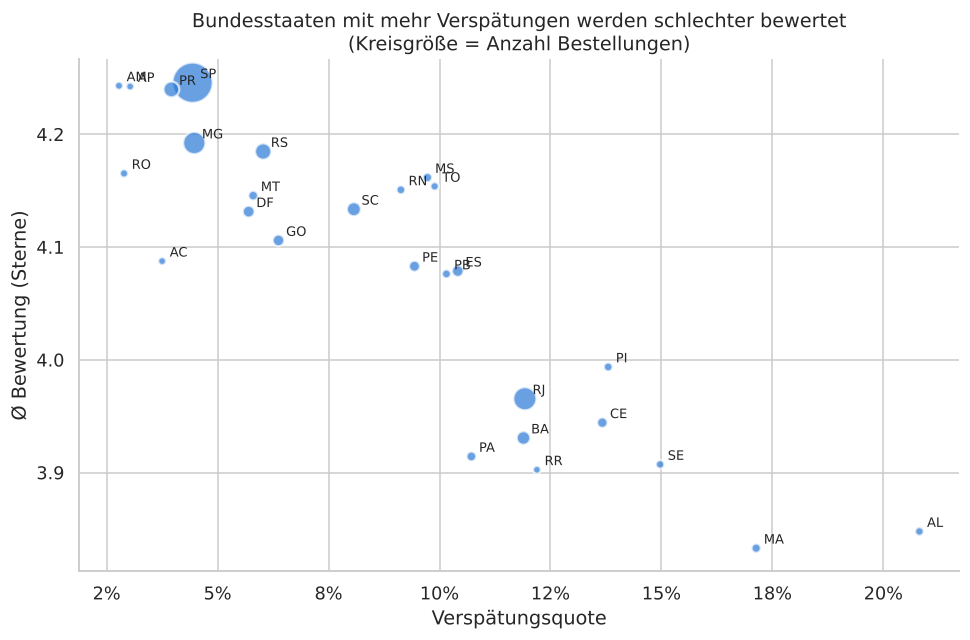

Spearman auf Ebene der 27 Bundesstaaten: rho = -0.88, p < 0,001


In [29]:
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(h3["Verspaetungsquote"], h3["Bewertung_Mittel"], s=h3["Bestellungen"] / 60 + 25,
           color=BLAU, alpha=0.7, edgecolor="white", linewidth=1.5)
for staat, zeile in h3.iterrows():
    ax.annotate(staat, (zeile["Verspaetungsquote"], zeile["Bewertung_Mittel"]),
                xytext=(5, 3), textcoords="offset points", fontsize=8.5)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set(title="Bundesstaaten mit mehr Verspätungen werden schlechter bewertet\n(Kreisgröße = Anzahl Bestellungen)",
       xlabel="Verspätungsquote", ylabel="Ø Bewertung (Sterne)")
plt.tight_layout(); plt.show()

rho_st, p_st = stats.spearmanr(h3["Verspaetungsquote"], h3["Bewertung_Mittel"])
print(f"Spearman auf Ebene der 27 Bundesstaaten: rho = {rho_st:.2f}, p {p_text(p_st)}")

---
## Phase 5 – Ergebnispräsentation

### Übersicht der Hypothesen

In [30]:
uebersicht = pd.DataFrame({
    "Hypothese": ["H1: Verspätete schlechter bewertet", "H2: Mehr Verzögerung → schlechtere Bewertung",
                  "H3: Verspätungsquote unterscheidet sich nach Bundesstaat", "H4: Lieferzeit hängt mit Bewertung zusammen"],
    "Test": ["Mann-Whitney-U", "Spearman + Kruskal-Wallis", "Chi²-Unabhängigkeitstest", "Spearman"],
    "Kennzahl": [f"Ø {puenktlich.mean():.2f} vs. {verspaetet.mean():.2f} Sterne, |r| = {abs(r):.2f}",
                 f"rho = {rho_alle:.2f} (nur verspätete: {rho_spaet:.2f})",
                 f"{h3['Verspaetungsquote'].min():.0%}–{h3['Verspaetungsquote'].max():.0%}, Cramérs V = {cramers_v:.2f}",
                 f"rho = {rho_lz:.2f} (nur pünktliche: {rho_lz_p:.2f})"],
    "p-Wert": [p, p_alle, p_chi, p_lz],
    "Ergebnis": ["bestätigt", "bestätigt", "bestätigt", "bestätigt (schwächer)"],
})
uebersicht.style.format({"p-Wert": lambda v: "< 0,001" if v < 0.001 else f"{v:.3f}"}).hide(axis="index")

Hypothese,Test,Kennzahl,p-Wert,Ergebnis
H1: Verspätete schlechter bewertet,Mann-Whitney-U,"Ø 4.29 vs. 2.27 Sterne, |r| = 0.28","< 0,001",bestätigt
H2: Mehr Verzögerung → schlechtere Bewertung,Spearman + Kruskal-Wallis,rho = -0.18 (nur verspätete: -0.40),"< 0,001",bestätigt
H3: Verspätungsquote unterscheidet sich nach Bundesstaat,Chi²-Unabhängigkeitstest,"3%–21%, Cramérs V = 0.13","< 0,001",bestätigt
H4: Lieferzeit hängt mit Bewertung zusammen,Spearman,rho = -0.23 (nur pünktliche: -0.13),"< 0,001",bestätigt (schwächer)


### Antwort auf die Forschungsfrage
1. **Lieferverzögerungen hängen stark mit schlechteren Bewertungen zusammen.** Verspätete Bestellungen erhalten im Schnitt rund 2 Sterne weniger, und mit jedem zusätzlichen Tag Verspätung sinkt die Bewertung weiter.
2. **Verzögerungen treten regional sehr unterschiedlich auf**, besonders häufig im **Nordosten** (AL, MA, SE, PI, CE) und in **Rio de Janeiro**.
3. Die reine **Lieferzeit** spielt eine geringere Rolle als die **Einhaltung des angekündigten Termins**.

### Handlungsempfehlungen für Olist
- **Realistische Liefertermine ankündigen**, vor allem für Bundesstaaten mit hoher Verspätungsquote. Ein etwas späteres, aber eingehaltenes Datum ist besser als ein gebrochenes Versprechen.
- **Logistik im Nordosten und in RJ prüfen** (z. B. Versanddienstleister, regionale Lager).
- **Proaktiv kommunizieren:** Kunden bei absehbarer Verspätung informieren, um 1-Stern-Bewertungen abzufangen.
- **Monitoring:** Die Verspätungsquote je Bundesstaat als laufende Kennzahl (KPI) beobachten.

### Grenzen der Analyse
- **Korrelation ≠ Kausalität:** Wir zeigen Zusammenhänge, keinen Beweis für Ursache und Wirkung. Andere Faktoren (Produktqualität, Verkäufer, Preis) haben wir nicht betrachtet.
- Nur **zugestellte** Bestellungen wurden analysiert; stornierte oder nie angekommene Bestellungen fehlen, obwohl sie vermutlich besonders schlecht bewertet werden.
- Die Daten sind **2016–2018** und stammen aus **Brasilien** – eine Übertragung auf heute oder auf Deutschland ist nur eingeschränkt möglich.
- Kleine Bundesstaaten haben wenige Bestellungen, ihre Quoten sind daher unsicherer.
- Bewertungen sind freiwillig – unzufriedene Kunden bewerten möglicherweise häufiger (Selektionseffekt).

---
*Erstellt mit der Methode Vibe Coding: Der Python-Code wurde mit Unterstützung eines Sprachmodells (Claude, Anthropic) erzeugt, von der Gruppe ausgeführt, geprüft und interpretiert. Versioniert mit Git/GitHub.*